# Классификация ботов

[TODO]: добавить описание и везде заключить названия в `апострофы`

# Подготовка данных

## Загрузка датафреймов

In [1]:
import numpy as np
import pandas as pd

train = pd.read_csv(
    'data/train.csv',
    parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'],
)
test = pd.read_csv(
    'data/test.csv',
    parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'],
)
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])

print(train.shape, test.shape, events.shape)
print('доля ботов в train:', train.target.mean().round(4))
train.head()

(11091, 5) (4909, 4) (328905, 14)
доля ботов в train: 0.0811


,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0


In [2]:
events.head()

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,200,item_view,desktop,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,100,search_results_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN
2,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0
3,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN
4,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN


## Первичная предобработка датафреймов

Осуществим первичню (безусловную) предобработку признаков:
- Преобразуем строковые значения в нижний регистр

In [3]:
trsin = train.apply(lambda x: x.str.lower() if (x.dtype == 'strint') else x)
test = test.apply(lambda x: x.str.lower() if (x.dtype == 'string') else x)
events = events.apply(lambda x: x.str.lower() if (x.dtype == 'string') else x)

## Анализ датафреймов `train` и `test`

### Проверка качества датафреймов:

In [4]:
train.info()
print()
test.info();

<class 'pandas.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          11091 non-null  str           
 1   cookie_created_at  11091 non-null  datetime64[us]
 2   window_start_ts    11091 non-null  datetime64[us]
 3   window_end_ts      11091 non-null  datetime64[us]
 4   target             11091 non-null  int64         
dtypes: datetime64[us](3), int64(1), str(1)
memory usage: 433.4 KB

<class 'pandas.DataFrame'>
RangeIndex: 4909 entries, 0 to 4908
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          4909 non-null   str           
 1   cookie_created_at  4909 non-null   datetime64[us]
 2   window_start_ts    4909 non-null   datetime64[us]
 3   window_end_ts      4909 non-null   datetime64[us]
dtypes: datetime64[us](3)

In [5]:
print(
    'Дубликатов cookie_id в train нет:',
    len(train['cookie_id'].drop_duplicates()) == len(train),
)
print(
    'Дубликатов cookie_id в test нет:',
    len(test['cookie_id'].drop_duplicates()) == len(test),
)
print(
    'Утечек из train в test нет:',
    len(np.intersect1d(train['cookie_id'], test['cookie_id'])) == 0,
)
print(
    'Для каждой записи в train есть зарегистрированные события:',
    np.isin(train['cookie_id'], events['cookie_id'].unique()).all(),
)
print(
    'Для каждой записи в test есть зарегистрированные события:',
    np.isin(test['cookie_id'], events['cookie_id'].unique()).all(),
)

Дубликатов cookie_id в train нет: True
Дубликатов cookie_id в test нет: True
Утечек из train в test нет: True
Для каждой записи в train есть зарегистрированные события: True
Для каждой записи в test есть зарегистрированные события: True


### Распределение таргета по временным признакам:

---
- по времени создания cookie:

Распределение даты создания cookie по классам:


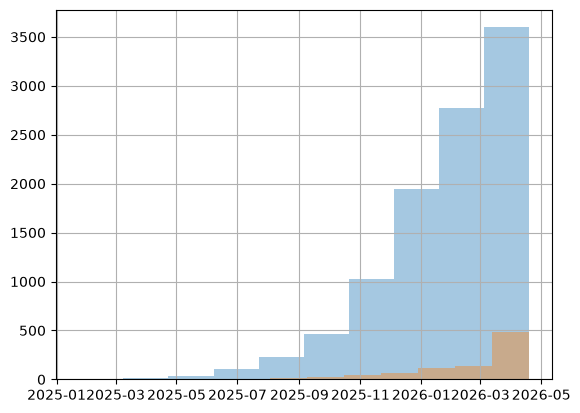

In [6]:
train.groupby('target')['cookie_created_at'].hist(alpha=0.4)
print('Распределение даты создания cookie по классам:')

---
- по дате начала окна:

Распределение даты создания cookie по классам:


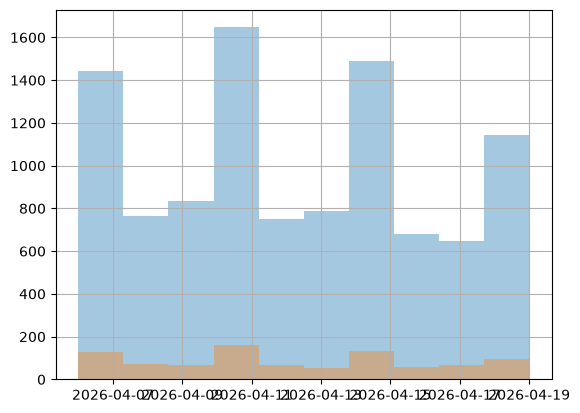

In [7]:
train.groupby('target')['window_start_ts'].hist(alpha=0.4)
print('Распределение даты создания cookie по классам:')

In [8]:
(
    train['window_end_ts'] - train['window_start_ts']
).value_counts()  # окно наблюдения всегда длится сутки

1 days    11091
Name: count, dtype: int64

## Анализ датафрейма `events`

### Распределение категориальных признаков:

---
- `event_name` - тип события
- `platform` - платформа пользователя
- `user_agent` - метаданные клиента

In [9]:
print(events.event_name.value_counts(), '\n')
print(events.platform.value_counts(), '\n')
print(events.user_agent.value_counts().iloc[[0, 1, 2, -2, -1]], '\n')

event_name
item_view               120817
search_results_view     100402
photo_swipe              36517
favorite_add             19049
seller_page_view         17403
contact_phone_show       11316
captcha_shown             7928
login                     6267
contact_chat_open         6125
contact_message_sent      3081
Name: count, dtype: int64 

platform
web        138792
android    126875
desktop     46866
ios         12269
iphone       4103
Name: count, dtype: int64 

user_agent
mozilla/5.0 (windows nt 10.0; win64; x64) applewebkit/537.36 (khtml, like gecko) chrome/119.0.0.0 yabrowser/23.11.0.0 safari/537.36    3737
mozilla/5.0 (windows nt 10.0; win64; x64; rv:119.0) gecko/20100101 firefox/119.0                                                       3670
mozilla/5.0 (windows nt 10.0; win64; x64) applewebkit/537.36 (khtml, like gecko) chrome/117.0.0.0 yabrowser/23.9.0.0 safari/537.36     3664
mozilla/5.0 (linux; android 12; sm-g991b) applewebkit/537.36 (khtml, like gecko) chrome/124.0

---
- `item_category` - категория объявления
- `item_location` - город
- `seller_type` - тип продавца

In [10]:
print(events.item_category.value_counts(), '\n')
print(events.item_location.value_counts().iloc[[0, 1, 2, -2, -1]], '\n')
print(events.seller_type.value_counts(), '\n')

item_category
avtomobili           20822
mebel                20541
bytovaya_tehnika     20161
hobbi                20020
elektronika          20002
uslugi               19869
odezhda              19846
kvartiry_arenda      19713
kvartiry_prodazha    19709
noutbuki             19583
detskie_tovary       19441
rabota               19387
telefony             19349
zhivotnye            19109
zapchasti            18433
Name: count, dtype: int64 

item_location
sankt-peterburg    39221
novosibirsk        37989
moskva             37964
irkutsk             3949
samara              3886
Name: count, dtype: int64 

seller_type
private    112631
pro         82421
Name: count, dtype: int64 



---
- `search_query` - поисковый запрос (только для события `search_results_view`)

In [11]:
events.search_query.value_counts()

search_query
toyota camry              919
кофемашина                919
клининг                   918
renault logan             916
kia rio 2019              908
                         ... 
стартер                   764
аккумулятор               761
samsung s23               757
macbook air m1            754
снять квартиру у метро    742
Name: count, Length: 120, dtype: int64

### Доля пропусков:

In [12]:
print('пропуски по колонкам:')
print(events.isna().mean().round(3))

пропуски по колонкам:
cookie_id        0.000
event_ts         0.000
eid              0.000
event_name       0.000
platform         0.000
user_agent       0.000
item_id          0.348
item_category    0.100
item_location    0.072
seller_type      0.407
search_query     0.695
search_page      0.695
pointer_x        0.670
pointer_y        0.670
dtype: float64


### Анализ источников пропусков:

---
1) `pointer_x` / `pointer_y` по типам событий
2) `search_query` / `search_page` по типам событий

In [13]:
print('все типы событий:', sorted(events['event_name'].unique()), '\n')

print('доля событий с непустым значением pointer_x:')
print(
    events[~events['pointer_x'].isna()]['event_name'].value_counts()
    / events['event_name'].value_counts(),
    '\n',
)
print('доля событий с непустым значением search_query:')
print(
    (
        events[~events['search_query'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)

все типы событий: ['captcha_shown', 'contact_chat_open', 'contact_message_sent', 'contact_phone_show', 'favorite_add', 'item_view', 'login', 'photo_swipe', 'search_results_view', 'seller_page_view'] 

доля событий с непустым значением pointer_x:
event_name
captcha_shown           0.272200
contact_chat_open       0.308245
contact_message_sent    0.322623
contact_phone_show      0.323259
favorite_add            0.349467
item_view               0.326568
login                   0.353439
photo_swipe             0.341923
search_results_view     0.330462
seller_page_view        0.336149
Name: count, dtype: float64 

доля событий с непустым значением search_query:
event_name
search_results_view    1.0
Name: count, dtype: float64 



---
3) `item_id` по типам событий
4) `seller_type` по типам событий

In [14]:
print('все типы событий:', sorted(events['event_name'].unique()), '\n')

print('доля событий с непустым значением item_id:')
print(
    (
        events[~events['item_id'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)
print('доля событий с непустым значением seller_type:')
print(
    (
        events[~events['seller_type'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)

все типы событий: ['captcha_shown', 'contact_chat_open', 'contact_message_sent', 'contact_phone_show', 'favorite_add', 'item_view', 'login', 'photo_swipe', 'search_results_view', 'seller_page_view'] 

доля событий с непустым значением item_id:
event_name
contact_chat_open       1.0
contact_message_sent    1.0
contact_phone_show      1.0
favorite_add            1.0
item_view               1.0
photo_swipe             1.0
seller_page_view        1.0
Name: count, dtype: float64 

доля событий с непустым значением seller_type:
event_name
contact_chat_open       0.915265
contact_message_sent    0.909120
contact_phone_show      0.906769
favorite_add            0.908342
item_view               0.909806
photo_swipe             0.912041
seller_page_view        0.911107
Name: count, dtype: float64 



---
5) `item_category` по типам событий
6) `item_location` по типам событий

In [15]:
print('все типы событий:', sorted(events['event_name'].unique()), '\n')

print('доля событий с непустым значением item_category:')
print(
    (
        events[~events['item_category'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)
print('доля событий с непустым значением item_location:')
print(
    (
        events[~events['item_location'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)

все типы событий: ['captcha_shown', 'contact_chat_open', 'contact_message_sent', 'contact_phone_show', 'favorite_add', 'item_view', 'login', 'photo_swipe', 'search_results_view', 'seller_page_view'] 

доля событий с непустым значением item_category:
event_name
contact_chat_open       0.941224
contact_message_sent    0.938656
contact_phone_show      0.941234
favorite_add            0.936637
item_view               0.940654
photo_swipe             0.941753
search_results_view     0.940340
seller_page_view        0.941562
Name: count, dtype: float64 

доля событий с непустым значением item_location:
event_name
contact_chat_open       0.969306
contact_message_sent    0.971113
contact_phone_show      0.971456
favorite_add            0.972072
item_view               0.969756
photo_swipe             0.968261
search_results_view     0.969005
seller_page_view        0.968913
Name: count, dtype: float64 



## Конструирование датафреймов `ev_tr` и `ev_te`

Соединим датафреймы `train` и `test` с датафреймом `events` по `cookie_id` с учетом ограничения: `window_start_ts <= event_ts < window_end_ts` для анализа и последующей агрегации событийных признаков.

In [16]:
def events_in_window(events, meta, include_target=False):
    meta_atributes = ['cookie_id', 'window_start_ts', 'window_end_ts']
    if include_target:
        meta_atributes += ['target']
    ev = events.merge(meta[meta_atributes], on='cookie_id')
    return ev[(ev.event_ts >= ev.window_start_ts) & (ev.event_ts < ev.window_end_ts)]


ev_tr = events_in_window(events, train, include_target=True)
ev_te = events_in_window(events, test)
print(len(ev_tr), len(ev_te))
print(ev_tr['target'].mean().round(3))

198436 89690
0.134


## Анализ датафреймов `ev_tr` и `ev_te`

### Проверка качества датафреймов (учет ограничений окна):

In [17]:
print(
    'Для каждой записи в train есть зарегистрированные события в окне:',
    len(ev_tr['cookie_id'].unique()) == len(train),
)
print(
    'Для каждой записи в test есть зарегистрированные события в окне:',
    len(ev_te['cookie_id'].unique()) == len(test),
)

Для каждой записи в train есть зарегистрированные события в окне: True
Для каждой записи в test есть зарегистрированные события в окне: True


In [18]:
ev_tr.info()

<class 'pandas.DataFrame'>
Index: 198436 entries, 0 to 239214
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   cookie_id        198436 non-null  str           
 1   event_ts         198436 non-null  datetime64[us]
 2   eid              198436 non-null  int64         
 3   event_name       198436 non-null  str           
 4   platform         198436 non-null  str           
 5   user_agent       198436 non-null  str           
 6   item_id          132819 non-null  float64       
 7   item_category    182802 non-null  str           
 8   item_location    188610 non-null  str           
 9   seller_type      120778 non-null  str           
 10  search_query     61717 non-null   str           
 11  search_page      61717 non-null   float64       
 12  pointer_x        66243 non-null   float64       
 13  pointer_y        66243 non-null   float64       
 14  window_start_ts  198436 non-null  da

### Не представленные в `ev_tr` категориальные значения:

In [19]:
ev_tr.info()

<class 'pandas.DataFrame'>
Index: 198436 entries, 0 to 239214
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   cookie_id        198436 non-null  str           
 1   event_ts         198436 non-null  datetime64[us]
 2   eid              198436 non-null  int64         
 3   event_name       198436 non-null  str           
 4   platform         198436 non-null  str           
 5   user_agent       198436 non-null  str           
 6   item_id          132819 non-null  float64       
 7   item_category    182802 non-null  str           
 8   item_location    188610 non-null  str           
 9   seller_type      120778 non-null  str           
 10  search_query     61717 non-null   str           
 11  search_page      61717 non-null   float64       
 12  pointer_x        66243 non-null   float64       
 13  pointer_y        66243 non-null   float64       
 14  window_start_ts  198436 non-null  da

---
- `event_name`
- `platform`
- `user_agent`
- `item_category`
- `item_location`
- `seller_type`
- `search_query`

In [20]:
print(
    'Каждое значение event_name из ev_te представлено в ev_tr:',
    np.isin(ev_te['event_name'].unique(), ev_tr['event_name'].unique()).all(),
    '\n',
)

print(
    f'Всего уникальных значений event_name в events: {len(events["event_name"].unique())}'
)
print(
    f'Всего уникальных значений event_name в ev_tr: {len(ev_tr["event_name"].unique())}',
    '\n',
    f'Недостающие значения: {set.difference(set(events["event_name"].unique()), ev_tr["event_name"].unique())}',
)
print(
    f'Всего уникальных значений event_name в ev_te: {len(ev_te["event_name"].unique())}',
    '\n',
    f'Недостающие значения: {set.difference(set(events["event_name"].unique()), ev_te["event_name"].unique())}',
    '\n',
)

print(
    'Каждое значение platform из ev_te представлено в ev_tr:',
    np.isin(ev_te['platform'].unique(), ev_tr['platform'].unique()).all(),
    '\n',
)
print(
    'Каждое значение user_agent из ev_te представлено в ev_tr:',
    np.isin(ev_te['user_agent'].unique(), ev_tr['user_agent'].unique()).all(),
)

print(
    'Каждое значение item_category из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['item_category'].dropna().unique(),
        ev_tr['item_category'].dropna().unique(),
    ).all(),
    '\n',
)

print(
    'Каждое значение item_location из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['item_location'].dropna().unique(),
        ev_tr['item_location'].dropna().unique(),
    ).all(),
    '\n',
)

print(
    'Каждое значение seller_type из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['seller_type'].dropna().unique(), ev_tr['seller_type'].dropna().unique()
    ).all(),
    '\n',
)

print(
    'Каждое значение search_query из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['search_query'].dropna().unique(), ev_tr['search_query'].dropna().unique()
    ).all(),
    '\n',
)

Каждое значение event_name из ev_te представлено в ev_tr: True 

Всего уникальных значений event_name в events: 10
Всего уникальных значений event_name в ev_tr: 9 
 Недостающие значения: {'captcha_shown'}
Всего уникальных значений event_name в ev_te: 9 
 Недостающие значения: {'captcha_shown'} 

Каждое значение platform из ev_te представлено в ev_tr: True 

Каждое значение user_agent из ev_te представлено в ev_tr: True
Каждое значение item_category из ev_te представлено в ev_tr: True 

Каждое значение item_location из ev_te представлено в ev_tr: True 

Каждое значение seller_type из ev_te представлено в ev_tr: True 

Каждое значение search_query из ev_te представлено в ev_tr: True 



### Распределение таргета по категориальным признакам:

---
- `user_agent`

In [21]:
mean_label_by_agents = ev_tr.groupby('user_agent')['target'].mean()

mean_label_by_agents[mean_label_by_agents > 0.3]

user_agent
avito/118.0 (android 11; m2101k6g) okhttp/4.11.0                                                                         0.446309
curl/8.1.2                                                                                                               0.383055
go-http-client/1.1                                                                                                       0.367372
mozilla/5.0 (macintosh; intel mac os x 10_15_7) applewebkit/537.36 (khtml, like gecko) chrome/122.0.0.0 safari/537.36    0.301066
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headlesschrome/114.0.0.0 safari/537.36            0.495474
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headlesschrome/118.0.0.0 safari/537.36            0.578972
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headlesschrome/120.0.0.0 safari/537.36            0.494769
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headless

---
- `event_name`

In [22]:
mean_label_by_event = ev_tr.groupby('event_name')['target'].mean()

mean_label_by_event[(mean_label_by_event < 0.06) | (mean_label_by_event > 0.15)]

event_name
favorite_add           0.059816
item_view              0.155614
login                  0.053077
search_results_view    0.150979
Name: target, dtype: float64

---
- `platform`

In [23]:
mean_label_by_platform = ev_tr.groupby('platform')['target'].mean()

mean_label_by_platform

platform
android    0.079586
desktop    0.179824
ios        0.052833
iphone     0.053420
web        0.179399
Name: target, dtype: float64

---
- `seller_type`

In [24]:
mean_label_by_seller = ev_tr.groupby('seller_type')['target'].mean()

print(mean_label_by_seller, '\n')
print(f'for NaN: {ev_tr[ev_tr["seller_type"].isna()]["target"].mean()}')

seller_type
private    0.120696
pro        0.138396
Name: target, dtype: float64 

for NaN: 0.1419815086662031


---
- `search_query`

In [25]:
mean_label_by = ev_tr.groupby('search_query')['target'].mean()

mean_label_by[mean_label_by > 0.19]

search_query
hyundai solaris      0.193424
skoda octavia        0.211470
автокресло           0.201629
грузоперевозки       0.236994
джинсы levis         0.203735
микроволновка        0.214567
мультиварка          0.195029
наушники airpods     0.197652
новостройка          0.199637
работа водителем     0.191901
работа грузчиком     0.197368
самокат взрослый     0.201536
смена 12 часов       0.197842
снять 1к квартиру    0.194231
удаленная работа     0.218750
Name: target, dtype: float64

### Распределение простейших агрегированных признаков:

In [26]:
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

desktop_script_user_agents = [
    'curl/8.1.2',
    'go-http-client/1.1',
    'node-fetch/3.3.2',
    'python-requests/2.31.0',
    'python-urllib3/2.0.7',
    'scrapy/2.11.0',
]
platform_ua_conflict_markers = {
    'android': ['iphone', 'ipad', 'windows', 'macintosh'] + desktop_script_user_agents,
    'ios': ['android', 'windows', 'linux', 'chrome'] + desktop_script_user_agents,
    'iphone': ['android', 'windows', 'linux'] + desktop_script_user_agents,
    'desktop': ['android', 'iphone', 'ipad'],
    'web': [],
}

In [ ]:
ev_tr_random_aggs = (
    ev_tr.sort_values('event_ts')
    .groupby(['target', 'cookie_id'])
    .agg(
        count=('event_ts', 'count'),
        common_event=('event_name', lambda x: x.mode().iat[0]),
        common_platform=('platform', lambda x: x.mode().iat[0]),
        common_user_agent=('user_agent', lambda x: x.mode().iat[0]),
        script_ua=(
            'user_agent',
            lambda x: np.isin(desktop_script_user_agents, x).any(),
        ),
        nunique_items=('item_id', 'nunique'),
        item_events=('item_id', lambda x: (~x.isna()).sum()),
        item_view_times=('event_name', lambda x: (x == 'item_view').sum()),
        search_times=('event_name', lambda x: (x == 'search_results_view').sum()),
        photo_swipe_times=('event_name', lambda x: (x == 'photo_swipe').sum()),
        favorite_add_times=('event_name', lambda x: (x == 'favorite_add').sum()),
        seller_view_times=('event_name', lambda x: (x == 'seller_page_view').sum()),
        login_times=('event_name', lambda x: (x == 'login').sum()),
        contact_show_times=('event_name', lambda x: (x == 'contact_phone_show').sum()),
        chat_open_times=('event_name', lambda x: (x == 'contact_chat_open').sum()),
        message_sent_times=('event_name', lambda x: (x == 'contact_message_sent').sum()),
        nunique_cats=('item_category', 'nunique'),
        loc_max_freq=(
            'item_location',
            lambda x: Counter(x[~x.isna()]).most_common(1)[0][1] / ((~x.isna()).sum() + 1) if (~x.isna()).any() else 0,
        ),
        seller_type_pro=('seller_type', lambda x: (x == 'pro').any()),
        seller_type_private=('seller_type', lambda x: (x == 'private').any()),
        seller_type_default=('seller_type', lambda x: x.isna().any()),
        seller_page_view_first=('event_name', lambda x: x.iloc[0] == 'seller_page_view'),
        search_page_max=('search_page', 'max'),
        search_page_first=(
            'search_page',
            lambda x: x[~x.isna()].iloc[0].item() if (~x.isna()).any() else 0,
        ),  # groupby preserves the order of rows within each group
        nunique_search_query=('search_query', 'nunique'),
        pointer_x_max_freq=(
            'pointer_x',
            lambda x: Counter(x[~x.isna()]).most_common(1)[0][1] if (~x.isna()).any() else 0,
        ),
        pointer_y_max_freq=(
            'pointer_y',
            lambda x: Counter(x[~x.isna()]).most_common(1)[0][1] if (~x.isna()).any() else 0,
        ),

        # switches_platform=('platform', lambda x: x.nunique() > 1),
        # switches_agent=('user_agent', lambda x: x.nunique() > 1),
    )
    .reset_index()
)

ev_tr_random_aggs.loc[ev_tr_random_aggs['search_page_max'].isna(), 'search_page_max'] = 0

ev_tr_random_aggs['item_events_per_unique_item'] = ev_tr_random_aggs['item_events'] / (
    ev_tr_random_aggs['nunique_items'] + 1
)
ev_tr_random_aggs['contact_show_times_per_unique_item'] = ev_tr_random_aggs[
    'contact_show_times'
] / (ev_tr_random_aggs['nunique_items'] + 1)
ev_tr_random_aggs['photo_swipe_per_unique_item'] = ev_tr_random_aggs['photo_swipe_times'] / (ev_tr_random_aggs['nunique_items'] + 1)
# ev_tr_random_aggs['changes_client_metadata'] = ev_tr_random_aggs['switches_platform'] | ev_tr_random_aggs['switches_agent']

ev_tr_random_aggs['search_per_item_view'] = ev_tr_random_aggs['search_times'] / (ev_tr_random_aggs['item_view_times'] + 1)
ev_tr_random_aggs['seller_view_per_item_view'] = ev_tr_random_aggs['seller_view_times'] / (ev_tr_random_aggs['item_view_times'] + 1)

ev_tr_random_aggs['message_sent_per_chat_open'] = ev_tr_random_aggs['message_sent_times'] / (ev_tr_random_aggs['chat_open_times'] + 1)

ev_tr_random_aggs['forbidden_ua_substrings'] = ev_tr_random_aggs['common_platform'].map(
    platform_ua_conflict_markers
)
ev_tr_random_aggs['client_metadata_conflict'] = [
    any(sub in text for sub in forbidden)
    for text, forbidden in zip(
        ev_tr_random_aggs['common_user_agent'],
        ev_tr_random_aggs['forbidden_ua_substrings'],
    )
]


ev_tr_random_aggs = ev_tr_random_aggs.drop(
    [
        'common_platform',
        'common_user_agent',
        'item_events',
        'item_view_times',
        'search_times',
        'photo_swipe_times',
        'contact_show_times',
        'message_sent_times',
        'forbidden_ua_substrings',
    ],
    axis=1,
)

ev_tr_random_aggs.info()

In [ ]:
# ev_tr_random_aggs[ev_tr_random_aggs['count'] < 5]['target'].value_counts()

ev_tr_random_aggs.groupby('count')['target'].mean().plot()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='nunique_items',
    hue='target',
    bins=80,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение кол-ва уникальных item_id')
plt.xlabel('Кол-во уникальных item_id')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='item_events_per_unique_item',
    hue='target',
    bins=20,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title(
    'Распределение отношения кол-ва событий с непустым item_id к кол-ву уникальных item_id'
)
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='contact_show_times_per_unique_item',
    hue='target',
    bins=20,
    alpha=0.5,
)

plt.yscale('log')
plt.title(
    'Распределение отношения кол-ва событий contact_phone_show к кол-ву уникальных item_id'
)
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='search_page_first',
    hue='target',
    bins=48,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение номера первой поисковой страницы за сессию')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='search_page_max',
    hue='target',
    bins=65,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение максимального номера поисковой страницы за сессию')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='nunique_search_query',
    hue='target',
    bins=20,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение кол-ва уникальных поисковых запросов')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='pointer_x_max_freq',
    hue='target',
    bins=15,
    binrange=(0, 15),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('log')
plt.title('Распределение максимальной частоты значения pointer_x')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='pointer_y_max_freq',
    hue='target',
    bins=15,
    binrange=(0, 15),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('log')
plt.title('Распределение максимальной частоты значения pointer_y')
plt.show()

### Распределение агрегированной разницы во времени между событиями:

In [ ]:
ev_plus_diff = ev_tr.copy()

ev_plus_diff['time_diff'] = (
    ev_plus_diff.sort_values('event_ts')
    .groupby(['target', 'cookie_id'])['event_ts']
    .diff()
)
ev_plus_diff['time_diff'] = ev_plus_diff['time_diff'].dt.total_seconds()

ev_plus_diff.sort_values('event_ts').head(3)

In [ ]:
diffs_stats = (
    ev_plus_diff.groupby(['cookie_id', 'target'])
    .agg(
        count=('event_ts', 'count'),
        time_diff_min=('time_diff', 'min'),
        time_diff_mean=('time_diff', 'mean'),
        time_diff_median=('time_diff', 'median'),
        time_diff_std=('time_diff', 'std'),
        time_diff_nunique=('time_diff', 'nunique'),
        time_diff_max_freq=('time_diff', lambda x: Counter(x).most_common(1)[0][1]),
    )
    .reset_index()
)
diffs_stats.loc[
    diffs_stats['count'] == 1, ['time_diff_nunique', 'time_diff_max_freq']
] = 0
diffs_stats.loc[
    diffs_stats['count'] == 1,
    ['time_diff_min', 'time_diff_mean', 'time_diff_median', 'time_diff_std'],
] = -1
diffs_stats.loc[diffs_stats['time_diff_std'].isna(), 'time_diff_std'] = -1

diffs_stats.info()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_min',
    hue='target',
    bins=100,
    binrange=(0, 600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение минимального времени между событиями (log scale Y)')
plt.xlabel('Минимальная разница во времени')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_mean',
    hue='target',
    bins=300,
    binrange=(0, 3600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение среднего времени между событиями (log scale Y)')
plt.xlabel('Средняя разница во времени')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_median',
    hue='target',
    bins=300,
    binrange=(0, 3600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение медианного времени между событиями (log scale Y)')
plt.xlabel('Медианная разница во времени')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_std',
    hue='target',
    bins=300,
    binrange=(0, 3600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение СКО времени между событиями (log scale Y)')
plt.xlabel('СКО разницы во времени')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_nunique',
    hue='target',
    bins=100,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение числа уникальных значений времени между событиями')
plt.xlabel('Кол-во уникальных значений разницы во времени')
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_max_freq',
    hue='target',
    bins=70,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Максимальная частота значения времени между событиями (log scale Y)')
plt.xlabel('Максимальная частота значения разницы во времени')
plt.show()

## Обучающая и тестовая выборки

### Для бейзлайна:

In [ ]:
def basic_features(ev, meta):
    g = ev.groupby('cookie_id')
    f = pd.DataFrame(
        {
            'n_events': g.size(),
            'item_nunique': g.item_id.nunique(),
        }
    )
    f = meta[['cookie_id']].merge(f.reset_index(), on='cookie_id', how='left')
    return f.fillna(0)


Xtr_baseline = basic_features(ev_tr.drop('target', axis=1), train)
Xte_baseline = basic_features(ev_te, test)
ytr = train.target.values

Xtr_baseline.head()

### Для модели:

In [ ]:
def complex_features(ev, meta):
    f = (
        ev.sort_values('event_ts')
        .groupby('cookie_id')
        .agg(
            common_event=('event_name', lambda x: x.mode().iat[0]),
            common_platform=('platform', lambda x: x.mode().iat[0]),
            common_user_agent=('user_agent', lambda x: x.mode().iat[0]),
            script_ua=(
                'user_agent',
                lambda x: np.isin(desktop_script_user_agents, x).any(),
            ),
            nunique_items=('item_id', 'nunique'),
            item_events=('item_id', lambda x: (~x.isna()).sum()),
            item_view_times=('event_name', lambda x: (x == 'item_view').sum()),
            search_times=('event_name', lambda x: (x == 'search_results_view').sum()),
            photo_swipe_times=('event_name', lambda x: (x == 'photo_swipe').sum()),
            favorite_add_times=('event_name', lambda x: (x == 'favorite_add').sum()),
            seller_view_times=('event_name', lambda x: (x == 'seller_page_view').sum()),
            login_times=('event_name', lambda x: (x == 'login').sum()),
            contact_show_times=('event_name', lambda x: (x == 'contact_phone_show').sum()),
            chat_open_times=('event_name', lambda x: (x == 'contact_chat_open').sum()),
            message_sent_times=('event_name', lambda x: (x == 'contact_message_sent').sum()),
            nunique_cats=('item_category', 'nunique'),
            loc_max_freq=(
                'item_location',
                lambda x: Counter(x[~x.isna()]).most_common(1)[0][1] / ((~x.isna()).sum() + 1) if (~x.isna()).any() else 0,
            ),
            seller_type_pro=('seller_type', lambda x: (x == 'pro').any()),
            seller_type_private=('seller_type', lambda x: (x == 'private').any()),
            seller_type_default=('seller_type', lambda x: x.isna().any()),
            seller_page_view_first=('event_name', lambda x: x.iloc[0] == 'seller_page_view'),
            search_page_max=('search_page', 'max'),
            search_page_first=(
                'search_page',
                lambda x: x[~x.isna()].iloc[0].item() if (~x.isna()).any() else 0,
            ),  # groupby preserves the order of rows within each group
            nunique_search_query=('search_query', 'nunique'),
            pointer_x_max_freq=(
                'pointer_x',
                lambda x: Counter(x[~x.isna()]).most_common(1)[0][1] if (~x.isna()).any() else 0,
            ),
            pointer_y_max_freq=(
                'pointer_y',
                lambda x: Counter(x[~x.isna()]).most_common(1)[0][1] if (~x.isna()).any() else 0,
            ),
        )
        .reset_index()
    )

    f.loc[f['search_page_max'].isna(), 'search_page_max'] = 0

    f['item_events_per_unique_item'] = f['item_events'] / (
        f['nunique_items'] + 1
    )
    f['contact_show_times_per_unique_item'] = f[
        'contact_show_times'
    ] / (f['nunique_items'] + 1)
    f['photo_swipe_per_unique_item'] = f['photo_swipe_times'] / (f['nunique_items'] + 1)
    # f['changes_client_metadata'] = f['switches_platform'] | f['switches_agent']

    f['search_per_item_view'] = f['search_times'] / (f['item_view_times'] + 1)
    f['seller_view_per_item_view'] = f['seller_view_times'] / (f['item_view_times'] + 1)

    f['message_sent_per_chat_open'] = f['message_sent_times'] / (f['chat_open_times'] + 1)

    f['forbidden_ua_substrings'] = f['common_platform'].map(
        platform_ua_conflict_markers
    )
    f['client_metadata_conflict'] = [
        any(sub in text for sub in forbidden)
        for text, forbidden in zip(
            f['common_user_agent'],
            f['forbidden_ua_substrings'],
        )
    ]


    f = f.drop(
        [
            'common_platform',
            'common_user_agent',
            'item_events',
            'item_view_times',
            'search_times',
            'photo_swipe_times',
            'contact_show_times',
            'message_sent_times',
            'forbidden_ua_substrings',
        ],
        axis=1,
    )

    ev_plus_diff = ev_tr.copy()

    ev_plus_diff['time_diff'] = (
        ev_plus_diff.sort_values('event_ts')
        .groupby('cookie_id')['event_ts']
        .diff()
    )
    ev_plus_diff['time_diff'] = ev_plus_diff['time_diff'].dt.total_seconds()

    diffs_stats = (
        ev_plus_diff.groupby(['cookie_id', 'target'])
        .agg(
            count=('event_ts', 'count'),
            time_diff_min=('time_diff', 'min'),
            time_diff_mean=('time_diff', 'mean'),
            time_diff_median=('time_diff', 'median'),
            time_diff_std=('time_diff', 'std'),
            time_diff_nunique=('time_diff', 'nunique'),
            time_diff_max_freq=('time_diff', lambda x: Counter(x).most_common(1)[0][1]),
        )
        .reset_index()
    )
    diffs_stats.loc[
        diffs_stats['count'] == 1, ['time_diff_nunique', 'time_diff_max_freq']
    ] = 0
    diffs_stats.loc[
        diffs_stats['count'] == 1,
        ['time_diff_min', 'time_diff_mean', 'time_diff_median', 'time_diff_std'],
    ] = -1
    diffs_stats.loc[diffs_stats['time_diff_std'].isna(), 'time_diff_std'] = -1

    f = meta[['cookie_id']].merge(f.reset_index(drop=True), on='cookie_id', how='left')
    f = f.merge(diffs_stats.reset_index(drop=True), on='cookie_id', how='left')
    return f


Xtr = complex_features(ev_tr.drop('target', axis=1), train)
Xte = complex_features(ev_te, test)

Xtr.head()

# Валидация

Тест лежит **позже** трейна по времени, поэтому и валидацию честно делать по времени, а не
случайным сплитом.

Метрику берём из `metric.py` — это ровно тот код, которым считает проверяющая система.
Своя реализация почти наверняка разойдётся с официальной на одинаковых `score`:
их нельзя разделять, группа равных значений отмечается целиком.

In [ ]:
ev_tr.event_ts.max() < ev_te.event_ts.min()

## Бейзлайн

In [ ]:
from sklearn.ensemble import RandomForestClassifier

from metric import (
    precision_at_recall,
)  # официальная реализация, ей же считает автопроверка

is_valid = train.window_start_ts.ge('2026-04-17').values
cols = ['n_events', 'item_nunique']

model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0)
model.fit(Xtr_baseline.loc[~is_valid, cols], ytr[~is_valid])
p_va = model.predict_proba(Xtr_baseline.loc[is_valid, cols])[:, 1]

print('P@R0.7 на валидации:', round(precision_at_recall(ytr[is_valid], p_va), 4))
print('доля ботов (это уровень константы):', round(ytr[is_valid].mean(), 4))

## Модель:

In [ ]:
from catboost import CatBoostClassifier

is_valid = train.window_start_ts.ge('2026-04-17').values

cols = Xtr.columns.copy()
cols = cols[cols != 'cookie_id']
cols = cols[cols != 'client_metadata_conflict']
cat_features = ['common_event']

model = CatBoostClassifier(iterations=50,
                           depth=5,
                           learning_rate=0.4,
                           loss_function='Logloss',
                           verbose=True,
                           cat_features=cat_features

)
model.fit(Xtr.loc[~is_valid, cols], ytr[~is_valid])
p_va = model.predict_proba(Xtr.loc[is_valid, cols])[:, 1]

print('P@R0.7 на валидации:', round(precision_at_recall(ytr[is_valid], p_va), 4))
print('доля ботов (это уровень константы):', round(ytr[is_valid].mean(), 4))

# Сабмит

In [ ]:
model.fit(Xtr[cols], ytr)
sub = pd.DataFrame(
    {
        'cookie_id': Xte.cookie_id,
        'score': model.predict_proba(Xte[cols])[:, 1],
    }
)
assert len(sub) == len(test) and sub.score.between(0, 1).all()
sub.to_csv('submission.csv', index=False)
sub.head()